Author
*   Kumar Jayant



# **Association Rules using apriori algorithm and association rules**


In [ ]:
!pip install mlxtend

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import mlxtend
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
import plotly.express as px

# Suppress all warnings completely
warnings.filterwarnings('ignore')

In [ ]:
mlxtend.__version__

'0.23.4'

In [ ]:
# Load the data for 2009-10
file_path1 = "/content/online_retail_2009-10.csv"
df_0910 = pd.read_csv(file_path1, encoding='ISO-8859-1')
df_0910

,ï»¿Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/09 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/09 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/09 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/09 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/09 7:45,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,12/9/10 20:01,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,12/9/10 20:01,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,12/9/10 20:01,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,12/9/10 20:01,3.75,17530.0,United Kingdom


In [ ]:
# Load the data for 2010-11
file_path2 = "/content/online_retail_2010-11.csv"
df_1011 = pd.read_csv(file_path2, encoding='ISO-8859-1')
df_1011

,ï»¿Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France


In [ ]:
# describe the dataframe from 2009-10
df_0910.describe(include='all')

,ï»¿Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,525461,525461,522533,525461.000000,525461,525461.000000,417534.000000,525461
unique,28816,4632,4681,NaN,25296,NaN,NaN,40
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,12/6/10 16:57,NaN,NaN,United Kingdom
freq,675,3516,3549,NaN,675,NaN,NaN,485852
mean,NaN,NaN,NaN,10.337667,NaN,4.688834,15360.645478,NaN
std,NaN,NaN,NaN,107.424110,NaN,146.126914,1680.811316,NaN
min,NaN,NaN,NaN,-9600.000000,NaN,-53594.360000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13983.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.100000,15311.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.210000,16799.000000,NaN


In [ ]:
# check the dataframe from 2009-10 for any missing values
df_0910.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   ï»¿Invoice   525461 non-null  object 
 1   StockCode    525461 non-null  object 
 2   Description  522533 non-null  object 
 3   Quantity     525461 non-null  int64  
 4   InvoiceDate  525461 non-null  object 
 5   Price        525461 non-null  float64
 6   Customer ID  417534 non-null  float64
 7   Country      525461 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.1+ MB


In [ ]:
# describe the dataframe from 2010-11
df_1011.describe(include='all')

,ï»¿Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,541910,541910,540456,541910.000000,541910,541910.000000,406830.000000,541910
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/11 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552234,NaN,4.611138,15287.684160,NaN
std,NaN,NaN,NaN,218.080957,NaN,96.759765,1713.603074,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


In [ ]:
# check the dataframe from 2010-11 for any missing values
df_1011.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   ï»¿Invoice   541910 non-null  object 
 1   StockCode    541910 non-null  object 
 2   Description  540456 non-null  object 
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  object 
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


Both the datasets from years 2009-10 and 2010-11 are clean and require no imputation.

We shall be merging dataframes from 2009-10 and 2010-11 vertically to get a bigger 2 year data set to be able to run market basket effectively.

In [ ]:
merged_df = pd.concat([df_0910, df_1011], axis=0)
merged_df

,ï»¿Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/09 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/09 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/09 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/09 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/09 7:45,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/11 12:50,4.95,12680.0,France


Rename the features "ï»¿Invoice" and "Customer ID" to tidy up the dataset

In [ ]:
merged_df.rename(columns={'ï»¿Invoice': 'Invoice', 'Customer ID	': 'Customer_ID	'}, inplace=True)

Preserve the dataframe as merged dataset for contributing on Kaggle for future learners

In [ ]:
merged_df.to_csv('merged_dataset_retail_2009_2001.csv', index=False)

Getting unique count of transactions and SKUs to starting trying with first set of Support and confidence levels

In [ ]:
count_transactions = merged_df['Invoice'].nunique()
count_transactions

53628

In [ ]:
count_skus = merged_df['StockCode'].nunique()
count_skus

5305

So we have 5,305 unique products and 53,625 transactions.

We have more than 5000 SKUs, it's a relatively large dataset so 5% (0.05) might be a good number to start with.

In [ ]:
# quick view of the dataframe before running the algorithm
merged_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/09 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/09 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/09 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/09 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/09 7:45,1.25,13085.0,United Kingdom


In [ ]:
# Clean whitespace and normalize text
merged_df['StockCode'] = merged_df['StockCode'].astype(str).str.strip()

merged_df['Description'] = (
    merged_df['Description'].astype(str).str.strip().str.title()
)

In [ ]:
# Concatenate StockCode	and Description with a hyphen in between for identifiability
merged_df['StockCode_merged'] = merged_df['StockCode'].astype(str) + '-' + merged_df['Description'].astype(str)

**Outcome:** Joining StockCode and Description makes the items readable, but it has a side effect. The same stock code is written with different descriptions in different invoices (about 1,200 codes have more than one), and missing descriptions become separate items such as `10002-Nan`. Each variant becomes its own column after encoding, so one product's support is split across several "items". Using one canonical name per stock code would avoid the split.

In [ ]:
# isolate Invoice and StockCode_merged to start MBA

df_mba = merged_df[['Invoice','StockCode_merged']]
df_mba.head()

,Invoice,StockCode_merged
0,489434,85048-15Cm Christmas Glass Ball 20 Lights
1,489434,79323P-Pink Cherry Lights
2,489434,79323W-White Cherry Lights
3,489434,"22041-Record Frame 7"" Single Size"
4,489434,21232-Strawberry Ceramic Trinket Box


In [ ]:
# Preparing the data in format that is usable with mlextend

# Group by orderNumber and aggregate the SKU IDs into a list for each order
order_items_series = df_mba.groupby('Invoice')['StockCode_merged'].apply(list)

itemset = order_items_series.tolist()

**Outcome:** Here the basket is defined: **one invoice = one basket**. Note that invoices starting with "C" are cancellations (8,292 of them), and some invoices hold only postage, bank charges or marketplace fees. They are still counted as baskets at this point, which adds to N, the denominator of support.

In [ ]:
df_mba.head(20)

,Invoice,StockCode_merged
0,489434,85048-15Cm Christmas Glass Ball 20 Lights
1,489434,79323P-Pink Cherry Lights
2,489434,79323W-White Cherry Lights
3,489434,"22041-Record Frame 7"" Single Size"
4,489434,21232-Strawberry Ceramic Trinket Box
5,489434,22064-Pink Doughnut Trinket Pot
6,489434,21871-Save The Planet Mug
7,489434,21523-Fancy Font Home Sweet Home Doormat
8,489435,22350-Cat Bowl
9,489435,"22349-Dog Bowl , Chasing Ball Design"


In [ ]:
itemset[0:3]

[['85048-15Cm Christmas Glass Ball 20 Lights',
  '79323P-Pink Cherry Lights',
  '79323W-White Cherry Lights',
  '22041-Record Frame 7" Single Size',
  '21232-Strawberry Ceramic Trinket Box',
  '22064-Pink Doughnut Trinket Pot',
  '21871-Save The Planet Mug',
  '21523-Fancy Font Home Sweet Home Doormat'],
 ['22350-Cat Bowl',
  '22349-Dog Bowl , Chasing Ball Design',
  '22195-Heart Measuring Spoons Large',
  '22353-Lunchbox With Cutlery Fairy Cakes'],
 ['48173C-Door Mat Black Flock',
  '21755-Love Building Block Word',
  '21754-Home Building Block Word',
  '84879-Assorted Colour Bird Ornament',
  '22119-Peace Wooden Block Letters',
  '22142-Christmas Craft White Fairy',
  '22296-Heart Ivory Trellis Large',
  '22295-Heart Filigree Dove Large',
  '22109-Full English Breakfast Plate',
  '22107-Pizza Plate In Box',
  '22194-Black Diner Wall Clock',
  '35004B-Set Of 3 Black Flying Ducks',
  '82582-Area Patrolled Metal Sign',
  '21181-Please One Person  Metal Sign',
  '21756-Bath Building Bloc

In [ ]:
# initialise OnehotTransactions
one_hot_encoding = TransactionEncoder()

# fit and transform the data
one_hot_array = one_hot_encoding.fit(itemset).transform(itemset)

# convert the matrix to dataframe
one_hot_df = pd.DataFrame(one_hot_array, columns=one_hot_encoding.columns_)

# Taking a limited look on the new df
one_hot_df.head()

,10002-Inflatable Political Globe,10002-Nan,10002R-Robot Pencil Sharpner,10080-Check,10080-Groovy Cactus Inflatable,10080-Nan,10109-Bendy Colour Pencils,10109-Nan,10120-Doggy Rubber,10120-Zebra Invcing Error,...,gift_0001_40-Nan,gift_0001_50-Dotcomgiftshop Gift Voucher Â£50.00,gift_0001_50-Nan,gift_0001_60-Nan,gift_0001_70-Dotcomgiftshop Gift Voucher Â£70.00,gift_0001_70-Nan,gift_0001_80-Dotcomgiftshop Gift Voucher Â£80.00,gift_0001_80-Nan,gift_0001_90-Nan,m-Manual
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
print(one_hot_df.shape)
print(f'There are {one_hot_df.shape[0]} transactions and {one_hot_df.shape[1]} SKUs in the encoded dataframe')

(53628, 8985)
There are 53628 transactions and 8985 SKUs in the encoded dataframe


**Outcome:** 53,628 baskets × 8,985 columns. The column count is higher than the 5,305 unique stock codes because of the description variants noted above. The basket count includes cancellations and fee-only invoices. Both lower the support of real products.

In [ ]:
# Setup apriori rules/algorithms

# Start with support of 2% that is item sets are present in atleast 2% of the transactions
min_support = 0.02

frequent_itemsets = apriori(one_hot_df, min_support=min_support, use_colnames=True)
frequent_itemsets['percent support'] = (frequent_itemsets['support'] * 100)
frequent_itemsets.sort_values('support', ascending=False)

,support,itemsets,percent support
120,0.102465,(85123A-White Hanging Heart T-Light Holder),10.246513
64,0.079455,(22423-Regency Cakestand 3 Tier),7.945476
117,0.061908,(85099B-Jumbo Bag Red Retrospot),6.190796
110,0.052715,(84879-Assorted Colour Bird Ornament),5.271500
94,0.050328,(47566-Party Bunting),5.032819
...,...,...,...
87,0.020325,(22866-Hand Warmer Scotty Dog Design),2.032520
129,0.020288,"(82494L-Wooden Frame Antique White, 82482-Wood...",2.028791
126,0.020269,"(21231-Sweetheart Ceramic Trinket Box, 21232-S...",2.026926
112,0.020195,(84970L-Single Heart Zinc T-Light Holder),2.019467


**Outcome:** At a 2% bar, 130 itemsets clear Step 0. The White Hanging Heart T-Light Holder is the single most common product, in 10.2% of baskets, followed by the Regency Cakestand (7.9%) and Jumbo Bag Red Retrospot (6.2%). With almost 9,000 columns and a median product in well under 1% of baskets, 2% is a high bar: most of the catalogue is filtered out before any pair is counted.

In [ ]:
# Extracting itemsets where there are more than 1 items
frequent_itemsets_gt1 = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(lambda x: len(x) > 1)
].reset_index(drop=True)

# Display results sorted by support
frequent_itemsets_gt1.sort_values(by="support", ascending=False)

,support,itemsets,percent support
1,0.023234,"(85123A-White Hanging Heart T-Light Holder, 21...",2.323413
2,0.020530,"(85099B-Jumbo Bag Red Retrospot, 21931-Jumbo S...",2.053032
3,0.020288,"(82494L-Wooden Frame Antique White, 82482-Wood...",2.028791
0,0.020269,"(21231-Sweetheart Ceramic Trinket Box, 21232-S...",2.026926


**Outcome:** Only **4 pairs** survive at 2% support, and no triples:

| Pair | Support |
| --- | --- |
| White + Red Hanging Heart T-Light Holder | 2.32% |
| Jumbo Bag Red Retrospot + Jumbo Storage Bag Suki | 2.05% |
| Wooden Frame Antique White + Wooden Picture Frame White Finish | 2.03% |
| Sweetheart + Strawberry Ceramic Trinket Box | 2.03% |

Each pair is two variants of the same range (two colours of the T-light holder, two jumbo bags, two white frames, two trinket boxes).

In [ ]:
# Now we have the dataframe where support is >=2%
# We will now proceed to association rules that is confidence and lift
frequent_itemsets1 = frequent_itemsets.drop(columns=['percent support'])


minimum_threshold = 0.05
rules = association_rules(frequent_itemsets1, metric='confidence', min_threshold=minimum_threshold)

In [ ]:
rules.sort_values('confidence', ascending=False)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(21231-Sweetheart Ceramic Trinket Box),(21232-Strawberry Ceramic Trinket Box),0.028959,0.046394,0.020269,0.699936,15.086876,1.0,0.018926,3.178006,0.961563,0.367976,0.685337,0.568416
3,(21733-Red Hanging Heart T-Light Holder),(85123A-White Hanging Heart T-Light Holder),0.033471,0.102465,0.023234,0.694150,6.774504,1.0,0.019804,2.934563,0.881906,0.206155,0.659234,0.460451
6,(82494L-Wooden Frame Antique White),(82482-Wooden Picture Frame White Finish),0.037480,0.037965,0.020288,0.541294,14.257608,1.0,0.018865,2.097278,0.966071,0.367816,0.523191,0.537837
7,(82482-Wooden Picture Frame White Finish),(82494L-Wooden Frame Antique White),0.037965,0.037480,0.020288,0.534381,14.257608,1.0,0.018865,2.067183,0.966558,0.367816,0.516250,0.537837
5,(21931-Jumbo Storage Bag Suki),(85099B-Jumbo Bag Red Retrospot),0.044081,0.061908,0.020530,0.465736,7.523040,1.0,0.017801,1.755859,0.907060,0.240236,0.430478,0.398681
1,(21232-Strawberry Ceramic Trinket Box),(21231-Sweetheart Ceramic Trinket Box),0.046394,0.028959,0.020269,0.436897,15.086876,1.0,0.018926,1.724447,0.979143,0.367976,0.420104,0.568416
4,(85099B-Jumbo Bag Red Retrospot),(21931-Jumbo Storage Bag Suki),0.061908,0.044081,0.020530,0.331627,7.523040,1.0,0.017801,1.430216,0.924296,0.240236,0.300805,0.398681
2,(85123A-White Hanging Heart T-Light Holder),(21733-Red Hanging Heart T-Light Holder),0.102465,0.033471,0.023234,0.226752,6.774504,1.0,0.019804,1.249959,0.949699,0.206155,0.199974,0.460451


**Outcome:** Reading the rules table:

- **Confidence is directional.** Sweetheart → Strawberry Trinket Box is 70%, but Strawberry → Sweetheart is 44%, because Strawberry is the more common item (4.6% vs 2.9% of baskets).
- **The popularity effect is visible.** Red → White Hanging Heart has 69% confidence, while White → Red has only 23%. The White holder is in 10.2% of all baskets, so almost anything "leads" to it.
- **Lift is symmetric** and very high everywhere (6.8 to 15.1): each pair is bought together 7 to 15 times more often than chance. The two trinket boxes (15.1) and the two white frames (14.3) are the tightest pairs.
- Extra columns from mlxtend: *leverage* = support minus what chance predicts (about 0.02 for all rules); *conviction* > 1 means the rule fails less often than chance would suggest (highest: Sweetheart → Strawberry at 3.2).

In [ ]:
# count of rows in rules dataframe
print(f'There are {rules.shape[0]} combinations where the confidence is greater than {minimum_threshold}')

There are 8 combinations where the confidence is greater than 0.05


**Outcome:** With a minimum confidence of 5%, the confidence filter removes nothing: all 8 rules from the 4 pairs pass. At a more typical 50% bar, only 4 rules remain (Sweetheart → Strawberry, Red → White T-light holder, and the two frame rules).

In [ ]:
# Sort by confidence and export to a CSV file
rules.sort_values('confidence', ascending=False).to_csv('rules_confidence_metric.csv', index=False)

#  Scatter Plot of Support vs. Confidence (Color-Coded by Lift)

Rules in the top-right quadrant with high Lift represent "Golden Rules"—frequent combinations that strongly imply co-purchase.



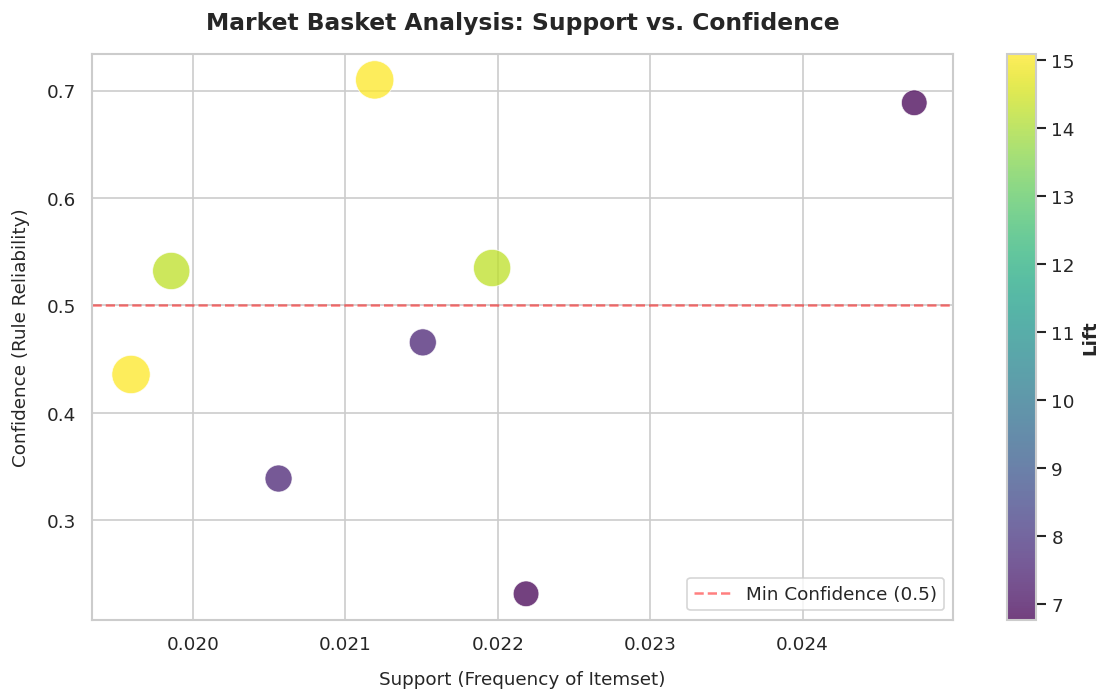

In [ ]:
# Set aesthetic style
sns.set_theme(style="whitegrid")

# Add jitter to support & confidence to prevent point overlapping (overplotting)
jitter_support = rules['support'] + np.random.normal(
    0, 0.001, size=len(rules)
)
jitter_confidence = rules['confidence'] + np.random.normal(
    0, 0.005, size=len(rules)
)

# Plot creation
plt.figure(figsize=(10, 6), dpi=120)

scatter = plt.scatter(
    x=jitter_support,
    y=jitter_confidence,
    c=rules['lift'],  # Color gradient mapped to Lift
    cmap='viridis',  # 'viridis', 'plasma', or 'YlOrRd'
    s=rules['lift']
    * 35,  # Size proportional to Lift for added dimension
    alpha=0.75,
    edgecolors='w',
    linewidth=0.5,
)

# Colorbar setup
cbar = plt.colorbar(scatter)
cbar.set_label('Lift', fontsize=11, fontweight='bold')

# Reference lines & Labels
plt.title(
    'Market Basket Analysis: Support vs. Confidence',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Support (Frequency of Itemset)', fontsize=11, labelpad=10)
plt.ylabel('Confidence (Rule Reliability)', fontsize=11, labelpad=10)

# Optional threshold reference lines
plt.axhline(
    y=0.5, color='red', linestyle='--', alpha=0.5, label='Min Confidence (0.5)'
)

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

**Outcome:** The rules form two groups: four rules with lift around 14–15 (trinket boxes and frames) and four with lift around 7 (jumbo bags and T-light holders). The random jitter (standard deviation 0.001 on support) is large relative to the real range, which is only 2.03%–2.32%, so the points' horizontal positions are partly noise. With just 8 rules, plotting without jitter would be more faithful.

**Graph of Rule Associations**

Reveals anchor products that drive purchases across multiple categories vs. isolated cross-sell pairs

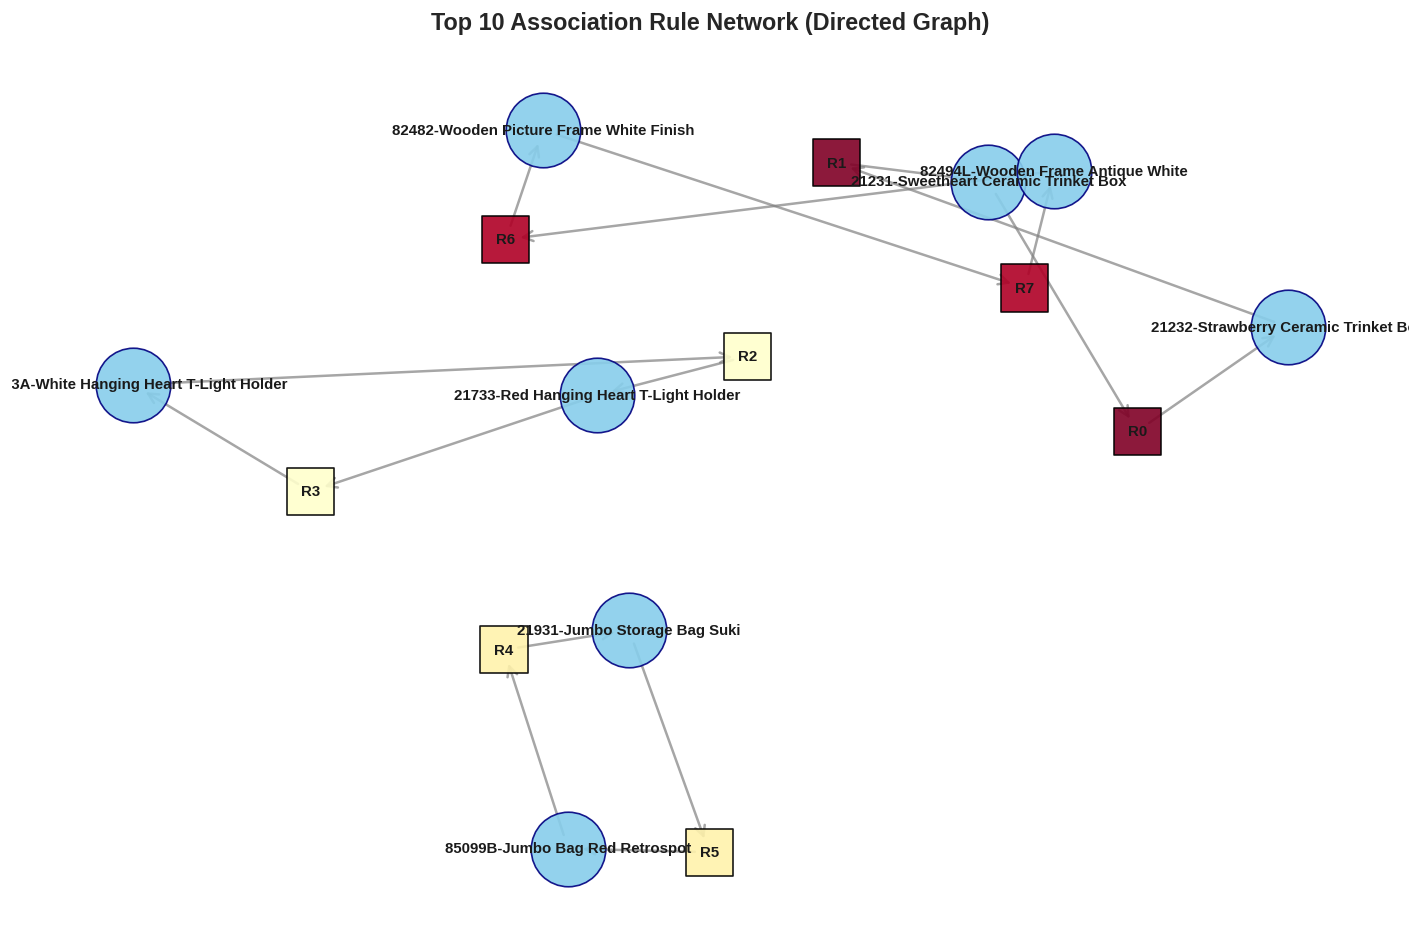

In [ ]:
# Set background style
plt.style.use("seaborn-v0_8-white") if "seaborn-v0_8-white" in plt.style.available else plt.style.use(
    "default"
)

# Sort and select Top N rules by Lift to avoid graph clutter
top_n = 10
top_rules = rules.sort_values(by="lift", ascending=False).head(top_n)

# Build Directed Graph using NetworkX
G = nx.DiGraph()

# Add nodes and edges from association rules
for idx, row in top_rules.iterrows():
    # Convert frozen sets to clean strings
    antecedent = ", ".join(list(row["antecedents"]))
    consequent = ", ".join(list(row["consequents"]))
    rule_node = f"Rule_{idx}"

    # Add item nodes and intermediate rule node
    G.add_node(antecedent, node_type="item")
    G.add_node(consequent, node_type="item")
    G.add_node(
        rule_node,
        node_type="rule",
        lift=row["lift"],
        confidence=row["confidence"],
    )

    # Add directed edges: Antecedent -> Rule Node -> Consequent
    G.add_edge(antecedent, rule_node, weight=row["confidence"])
    G.add_edge(rule_node, consequent, weight=row["lift"])

# Graph Layout Positioning
plt.figure(figsize=(12, 8), dpi=120)
pos = nx.spring_layout(G, k=0.8, seed=42)  # Spring layout spreads nodes cleanly

# Separate item nodes and rule nodes for distinct styling
item_nodes = [
    n for n, d in G.nodes(data=True) if d.get("node_type") == "item"
]
rule_nodes = [
    n for n, d in G.nodes(data=True) if d.get("node_type") == "rule"
]

# Get Lift values for rule nodes to set color gradient
rule_lifts = [G.nodes[n]["lift"] for n in rule_nodes]

# Draw Graph Components
# Draw Item Nodes (Product labels)
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=item_nodes,
    node_color="skyblue",
    node_size=2000,
    alpha=0.9,
    edgecolors="navy",
)

# Draw Rule Nodes (Sized by Lift)
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=rule_nodes,
    node_color=rule_lifts,
    cmap=plt.cm.YlOrRd,
    node_size=800,
    node_shape="s",  # Square shape for rules
    alpha=0.9,
    edgecolors="black",
)

# Draw Directed Arrows (Edges)
nx.draw_networkx_edges(
    G,
    pos,
    arrowstyle="->",
    arrowsize=15,
    edge_color="gray",
    width=1.5,
    alpha=0.7,
)

# Draw Node Labels
labels = {
    n: n if G.nodes[n].get("node_type") == "item" else f"R{n.split('_')[1]}"
    for n in G.nodes()
}
nx.draw_networkx_labels(
    G, pos, labels=labels, font_size=9, font_weight="bold"
)

# Add Title & Annotations
plt.title(
    f"Top {top_n} Association Rule Network (Directed Graph)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.axis("off")  # Turn off grid/axis box
plt.tight_layout()
plt.show()

**Outcome:** At a 2% bar the network is four isolated pairs, with no hub product linking several rules. There is no "anchor" product at this level of support. The label "3A-White Hanging Heart T-Light Holder" is a cut-off of `85123A-...`.

**Rule R3 (Bottom-Center Node)**

Antecedent (If): 21733-Red Hanging Heart T-Light Holder
Consequent (Then): 3A-White Hanging Heart T-Light Holder

Business Takeaway: This represents the inverse directional association rule: purchasing the Red Hanging Heart T-Light Holder strongly predicts the purchase of the White Hanging Heart T-Light Holder.

**Comment and outcome (added):** In numbers, R3 is 21733-Red Hanging Heart → 85123A-White Hanging Heart: support 2.3%, confidence 69%, lift 6.8. The reverse rule has only 23% confidence. "Strongly predicts" holds in this direction because the White holder is a best-seller; the lift of 6.8 confirms it is still a genuine pairing, not just popularity.

**Association Rule Matrix Heatmap**

Displays asymmetry in customer behavior (e.g., buying X strongly predicts buying Y, but buying Y might not predict buying X with equal confidence).

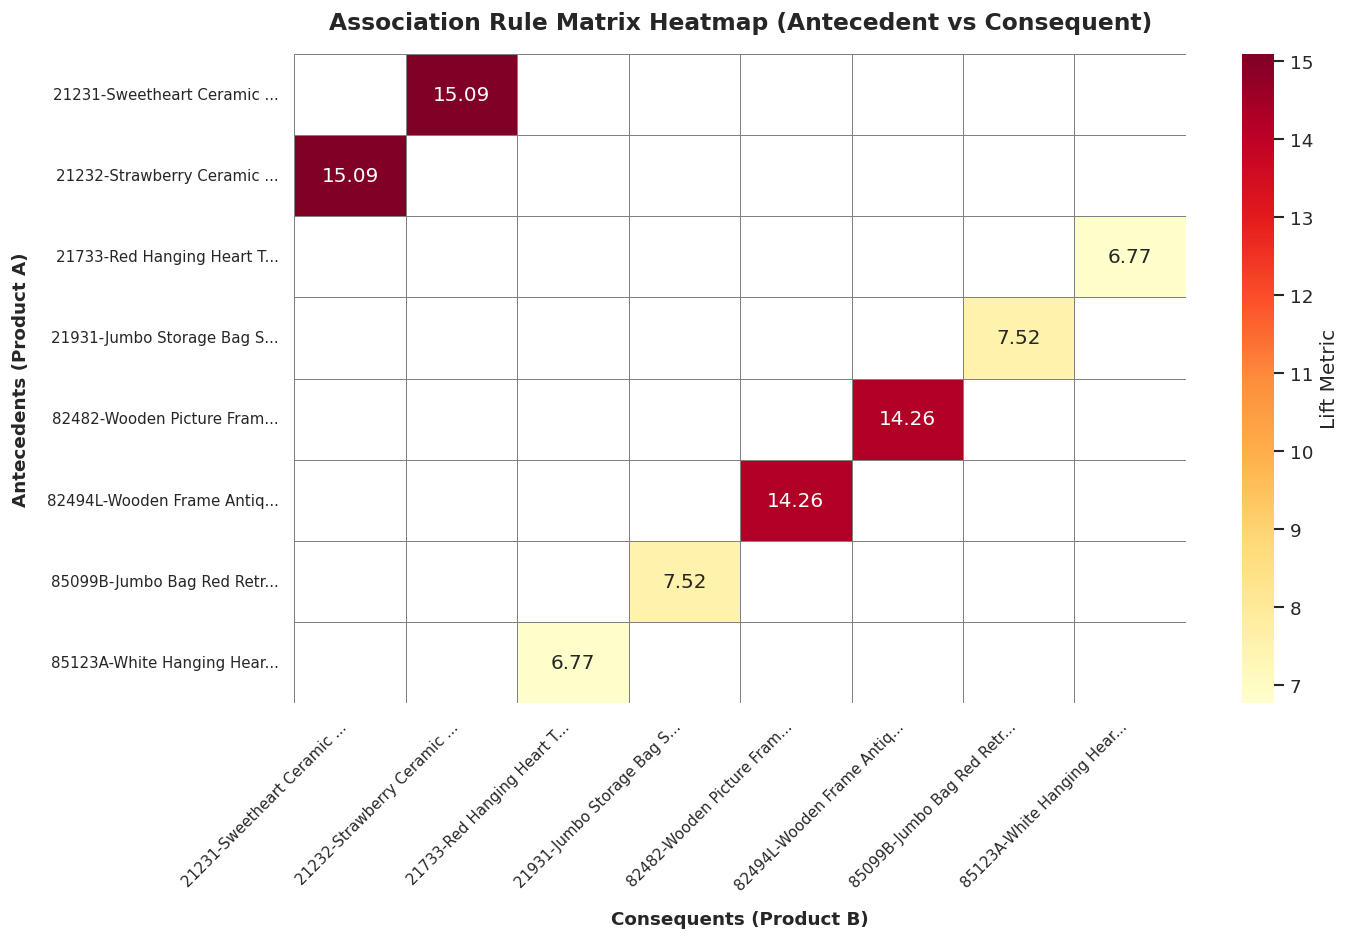

In [ ]:
# Set aesthetic visual style
sns.set_theme(style="white")

# Clean/Format string identifiers for readable axis labels
rules["antecedent_str"] = rules["antecedents"].apply(
    lambda x: ", ".join(list(x))
)
rules["consequent_str"] = rules["consequents"].apply(
    lambda x: ", ".join(list(x))
)

# Shorten long product names for clean visual display
rules["antecedent_str"] = rules["antecedent_str"].apply(
    lambda x: x[:25] + "..." if len(x) > 25 else x
)
rules["consequent_str"] = rules["consequent_str"].apply(
    lambda x: x[:25] + "..." if len(x) > 25 else x
)

# Select Top Rules by Lift to avoid overcrowding the heatmap
top_rules = rules.sort_values(by="lift", ascending=False).head(20)

# Pivot DataFrame into a 2D Matrix (Y-Axis: Antecedents, X-Axis: Consequents)
pivot_matrix = top_rules.pivot(
    index="antecedent_str", columns="consequent_str", values="lift"
)

# Create Heatmap Figure
plt.figure(figsize=(12, 8), dpi=120)

sns.heatmap(
    pivot_matrix,
    annot=True,  # Show Lift values inside the cells
    fmt=".2f",  # Format numbers to 2 decimal places
    cmap="YlOrRd",  # Color gradient: Yellow (Lower) -> Dark Red (High Lift)
    cbar_kws={"label": "Lift Metric"},
    linewidths=0.5,  # Add subtle borders between grid cells
    linecolor="gray",
    square=False,
)

# Add Titles and Labels
plt.title(
    "Association Rule Matrix Heatmap (Antecedent vs Consequent)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Consequents (Product B)", fontsize=11, fontweight="bold", labelpad=10)
plt.ylabel("Antecedents (Product A)", fontsize=11, fontweight="bold", labelpad=10)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()

plt.show()

**Outcome:** The heatmap is a mirror image across the diagonal because **lift is symmetric**: A → B and B → A always share the same lift. To show the asymmetry described above, use `values="confidence"` in the pivot; then Sweetheart → Strawberry (0.70) and Strawberry → Sweetheart (0.44) would differ.

**Top N Product Combinations Bar Chart (Ranked by Support or Lift)**

Gives marketing teams an immediate, prioritized list of top-performing bundles to feature in promotional campaigns.

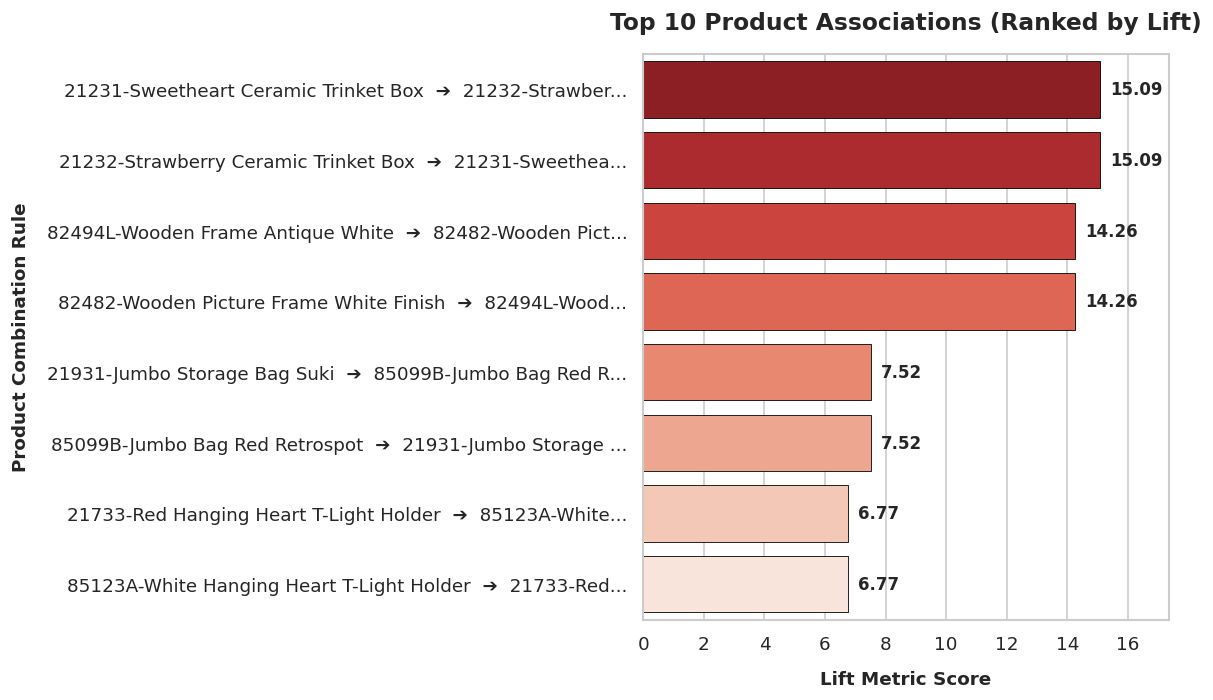

In [ ]:
# Set aesthetic visual style
sns.set_theme(style="whitegrid")


def plot_top_rules_bar_chart(
    rules_df, top_n=10, metric="lift", color_palette="Blues_r"
):
    """Generates a clean horizontal bar chart for the top N association rules.

    Parameters:
    -----------
    rules_df : pd.DataFrame
        DataFrame output from mlxtend's association_rules().
    top_n : int
        Number of top rules/combinations to display (default: 10).
    metric : str
        Metric to rank and display on X-axis: 'lift', 'support', or 'confidence'.
    color_palette : str
        Seaborn palette name for bar shading.
    """
    # 1. Prepare copy and format string identifiers
    df_plot = rules_df.copy()

    # Format antecedents and consequents into readable strings
    df_plot["antecedents_str"] = df_plot["antecedents"].apply(
        lambda x: ", ".join(list(x))
    )
    df_plot["consequents_str"] = df_plot["consequents"].apply(
        lambda x: ", ".join(list(x))
    )

    # Combine into a single rule string (Product A -> Product B)
    df_plot["rule_label"] = (
        df_plot["antecedents_str"] + "  ➔  " + df_plot["consequents_str"]
    )

    # Truncate extremely long titles so x-axis/labels remain clean
    df_plot["rule_label"] = df_plot["rule_label"].apply(
        lambda x: x[:55] + "..." if len(x) > 55 else x
    )

    # 2. Sort rules by specified metric and pick top N
    df_plot = df_plot.sort_values(by=metric, ascending=False).head(top_n)

    # 3. Render Horizontal Bar Chart
    plt.figure(figsize=(10, 6), dpi=120)

    ax = sns.barplot(
        data=df_plot,
        x=metric,
        y="rule_label",
        palette=color_palette,
        edgecolor="black",
        linewidth=0.5,
    )

    # 4. Add data value labels at the end of each bar
    for p in ax.patches:
        width = p.get_width()
        # Format label based on metric scale (e.g., percentage vs raw lift ratio)
        label_text = (
            f"{width:.1%}" if metric in ["support", "confidence"] else f"{width:.2f}"
        )
        ax.annotate(
            label_text,
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(6, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=10,
            fontweight="bold",
        )

    # 5. Graph Title and Axis Formatting
    title_metric = metric.capitalize()
    plt.title(
        f"Top {top_n} Product Associations (Ranked by {title_metric})",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )
    plt.xlabel(
        f"{title_metric} Metric Score", fontsize=11, fontweight="bold", labelpad=10
    )
    plt.ylabel("Product Combination Rule", fontsize=11, fontweight="bold", labelpad=10)

    # Expand X-axis margin slightly so data labels don't get clipped
    plt.xlim(0, df_plot[metric].max() * 1.15)
    plt.tight_layout()
    plt.show()

# 2. Plot Top 10 combinations ranked by Lift
plot_top_rules_bar_chart(rules, top_n=10, metric="lift", color_palette="Reds_r")

**Outcome:** Every pair appears twice (A → B and B → A) with identical lift, so the "top 10" here is really four pairs. Dropping the reverse duplicates gives a cleaner ranked list for a marketing team.

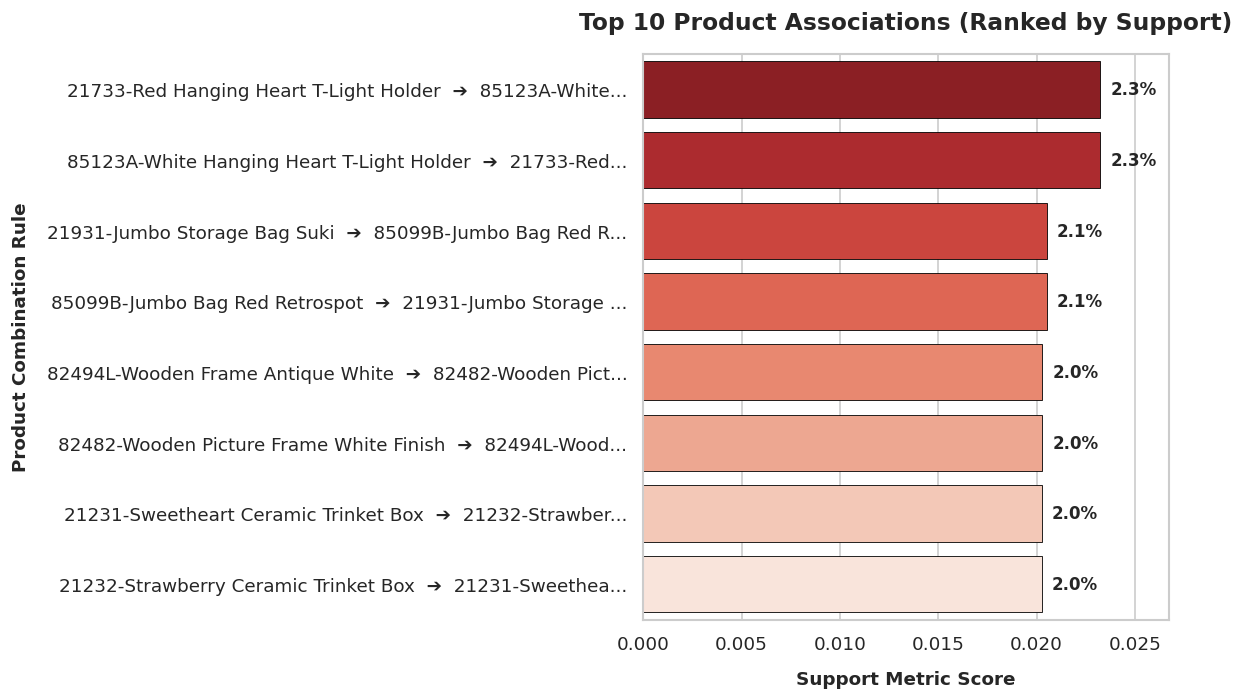

In [ ]:
# 3. Plot Top 10 combinations ranked by Support
plot_top_rules_bar_chart(rules, top_n=10, metric='support', color_palette="Reds_r")

**Outcome:** Ranked by support, the White + Red Hanging Heart pair comes first (2.3%) even though it has the lowest lift (6.8). The most common pair is not the most tightly linked one: support and lift answer different questions.

**Parallel Coordinates Plot**

Excellent for analyzing 3+ item bundles (e.g., customers who buy A and B almost always add C)

In [ ]:
# Filter for 2-Antecedent Rules (e.g., Antecedent 1 + Antecedent 2 -> Consequent)
# Convert frozensets to lists
rules["antecedent_list"] = rules["antecedents"].apply(list)
rules["consequent_list"] = rules["consequents"].apply(list)

# Filter rules that have exactly 2 antecedents and 1 consequent
multi_rules = rules[
    (rules["antecedent_list"].apply(len) == 2)
    & (rules["consequent_list"].apply(len) == 1)
].copy()

# Separate multi-item antecedents into Antecedent_1 and Antecedent_2
multi_rules["Antecedent_1"] = multi_rules["antecedent_list"].apply(
    lambda x: x[0]
)
multi_rules["Antecedent_2"] = multi_rules["antecedent_list"].apply(
    lambda x: x[1]
)
multi_rules["Consequent"] = multi_rules["consequent_list"].apply(
    lambda x: x[0]
)

# Sort and select Top N rules by Lift to avoid visual clutter
top_rules = multi_rules.sort_values(by="lift", ascending=False).head(20)

# Map string categorical labels to numerical IDs for Parallel Coordinates
# (Plotly parallel coordinates require numerical axes with custom text tick labels)
unique_items = list(
    set(top_rules["Antecedent_1"])
    | set(top_rules["Antecedent_2"])
    | set(top_rules["Consequent"])
)

item_to_id = {item: idx for idx, item in enumerate(unique_items)}
id_to_item = {idx: item for idx, item in enumerate(unique_items)}

top_rules["A1_id"] = top_rules["Antecedent_1"].map(item_to_id)
top_rules["A2_id"] = top_rules["Antecedent_2"].map(item_to_id)
top_rules["C_id"] = top_rules["Consequent"].map(item_to_id)

# Build Interactive Parallel Coordinates Diagram using Plotly
tick_vals = list(id_to_item.keys())
tick_text = [
    item[:25] + "..." if len(item) > 25 else item
    for item in id_to_item.values()
]

fig = px.parallel_coordinates(
    top_rules,
    dimensions=["A1_id", "A2_id", "C_id"],
    color="lift",
    labels={
        "A1_id": "Antecedent 1",
        "A2_id": "Antecedent 2",
        "C_id": "Consequent",
        "lift": "Lift",
    },
    color_continuous_scale=px.colors.diverging.Tealrose,
    title="Parallel Coordinates Plot: Multi-Step Pathway Analysis (Antecedent 1 → Antecedent 2 → Consequent)",
)

# Update axis tick labels to show readable product names
fig.update_layout(
    coloraxis_colorbar=dict(title="Lift"),
    font=dict(size=10),
)

for dim in fig.data[0].dimensions:
    dim.tickvals = tick_vals
    dim.ticktext = tick_text

fig.show()

**Outcome:** This plot produces no output because there are no rules with two antecedents at 2% support: no triple is frequent enough. A lower support bar would be needed to produce triples and make this plot meaningful.

**Other possible variants**

Creating association rules when metric is lift

In [ ]:
rules1 = association_rules(frequent_itemsets1, metric='lift', min_threshold=1)
rules1.sort_values('lift', ascending=False)


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(21231-Sweetheart Ceramic Trinket Box),(21232-Strawberry Ceramic Trinket Box),0.028959,0.046394,0.020269,0.699936,15.086876,1.0,0.018926,3.178006,0.961563,0.367976,0.685337,0.568416
1,(21232-Strawberry Ceramic Trinket Box),(21231-Sweetheart Ceramic Trinket Box),0.046394,0.028959,0.020269,0.436897,15.086876,1.0,0.018926,1.724447,0.979143,0.367976,0.420104,0.568416
6,(82494L-Wooden Frame Antique White),(82482-Wooden Picture Frame White Finish),0.037480,0.037965,0.020288,0.541294,14.257608,1.0,0.018865,2.097278,0.966071,0.367816,0.523191,0.537837
7,(82482-Wooden Picture Frame White Finish),(82494L-Wooden Frame Antique White),0.037965,0.037480,0.020288,0.534381,14.257608,1.0,0.018865,2.067183,0.966558,0.367816,0.516250,0.537837
5,(21931-Jumbo Storage Bag Suki),(85099B-Jumbo Bag Red Retrospot),0.044081,0.061908,0.020530,0.465736,7.523040,1.0,0.017801,1.755859,0.907060,0.240236,0.430478,0.398681
4,(85099B-Jumbo Bag Red Retrospot),(21931-Jumbo Storage Bag Suki),0.061908,0.044081,0.020530,0.331627,7.523040,1.0,0.017801,1.430216,0.924296,0.240236,0.300805,0.398681
3,(21733-Red Hanging Heart T-Light Holder),(85123A-White Hanging Heart T-Light Holder),0.033471,0.102465,0.023234,0.694150,6.774504,1.0,0.019804,2.934563,0.881906,0.206155,0.659234,0.460451
2,(85123A-White Hanging Heart T-Light Holder),(21733-Red Hanging Heart T-Light Holder),0.102465,0.033471,0.023234,0.226752,6.774504,1.0,0.019804,1.249959,0.949699,0.206155,0.199974,0.460451


**Outcome:** Filtering by lift ≥ 1 returns the same 8 rules, because every lift here is between 6.8 and 15.1. On this dataset a lift bar of 1 removes nothing; a higher bar (for example ≥ 10) would separate the trinket-box and frame pairs from the rest.

In [ ]:
# preserving results. Sort by lift and export to a CSV file
rules1.sort_values('lift', ascending=False).to_csv('rules_lift_metric.csv', index=False)

<div class="alert alert-block alert-info">
<h5>Manipulations and filtering </h5>
</div>

**NOTE**: You can do any kind of manipulations and filtering based on

* Based on lift, confidence, support thresholds
* Antecedents
* Any combination of these factors.

**End of notebook**